In [1]:
import pandas as pd
import matplotlib.pyplot as plt

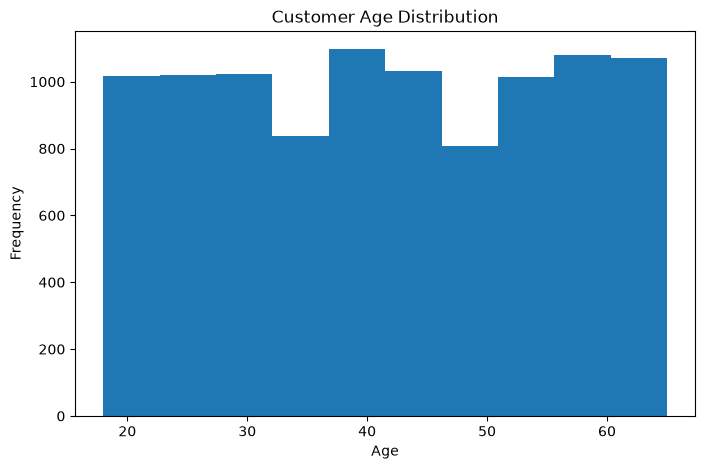

In [184]:
customers = pd.read_csv("datasets/customers.csv")


#cust_seg = customers.groupby("segment")["segment"].count()

#cust_seg.plot(kind="pie",
#             autopct="%1.1f%%",
#            figsize=(7,7))
#
#plt.title("customer segment pie chart")
#plt.ylabel("")
#plt.show

age_group_cust = customers.groupby("age")["age"].count().sort_values(ascending=False)

customers["age"].plot(
    kind="hist",
    bins=10,
    figsize=(8,5)
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.savefig("customer_age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

#age_group_cust.plot(kind="hist",
#                    bins=8,
#                    figsize=(8,8)
#                    )

#plt.title("Age Group Histogram")
#plt.xlabel("Age Group")
#plt.ylabel("No of customers")
#plt.show

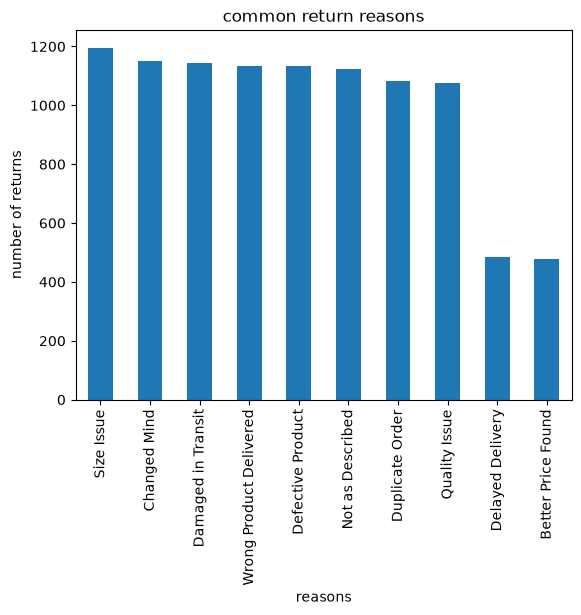

In [183]:
returns=pd.read_csv("datasets/returns.csv")

return_reasons=returns.groupby("reason")["reason"].count().sort_values(ascending=False).plot(
                kind="bar",title="common return reasons",
                xlabel="reasons",ylabel="number of returns")
plt.savefig("common_return_reasos.png", dpi=300, bbox_inches="tight")

<function matplotlib.pyplot.show(close=None, block=None)>

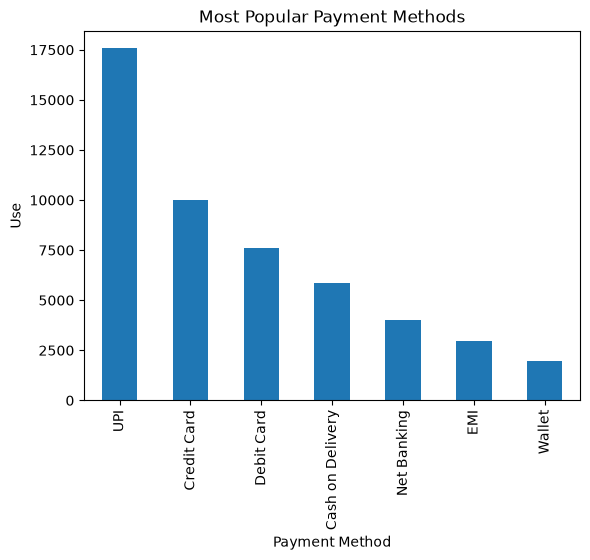

In [180]:
payments=pd.read_csv("datasets/payments.csv")
most_used_payment_mthd = payments.groupby("payment_method")["payment_method"].count().sort_values(ascending=False)
most_used_payment_mthd

pop_payment_mthd = most_used_payment_mthd.plot(kind="bar")
plt.title("Most Popular Payment Methods")

plt.xlabel("Payment Method")
plt.ylabel("Use")
plt.savefig("Most_popular_payment_method.png", dpi=300, bbox_inches="tight")
plt.show

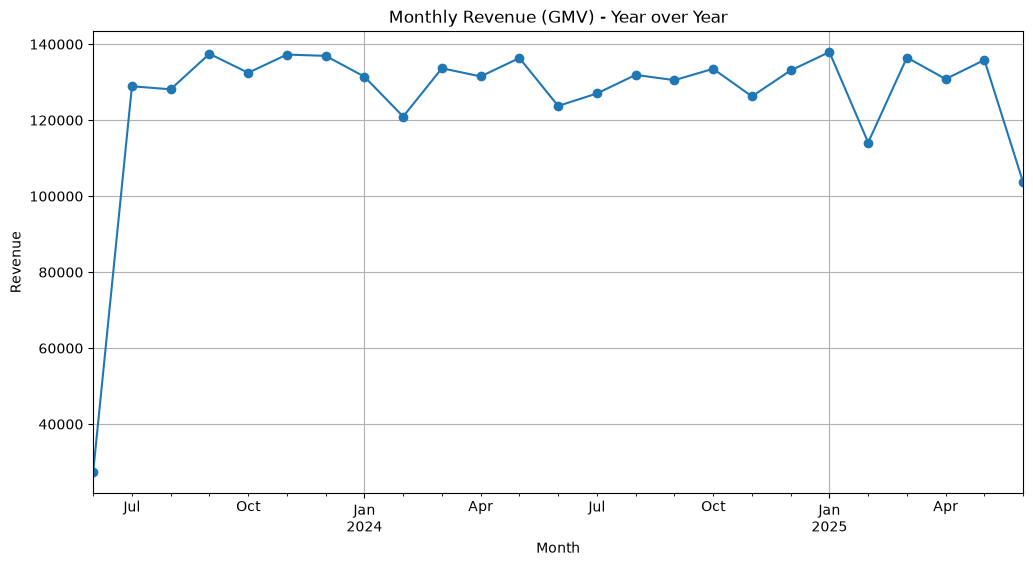

In [179]:
orders = pd.read_csv("datasets/orders.csv")

orders["order_date"]=pd.to_datetime(orders["order_date"],format="%d-%m-%Y")

orders["delivered_date"]=pd.to_datetime(orders["delivered_date"],format="%d-%m-%Y")

orders["Month"] = orders["order_date"].dt.to_period("M")

monthly_revenue = orders.groupby("Month")["final_amount"].sum()/1000

monthly_revenue

monthly_revenue.plot(figsize=(12,6), marker="o")

plt.title("Monthly Revenue (GMV) - Year over Year")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True)
plt.savefig("Monthly_Revenue.png", dpi=300, bbox_inches="tight")
plt.show()


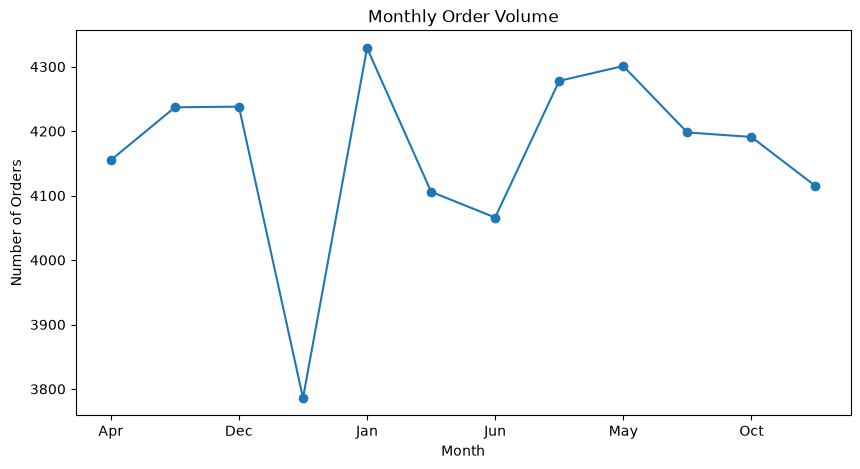

In [177]:
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["Month"] = orders["order_date"].dt.strftime("%b")
monthly_orders = (
    orders.groupby("Month")["order_id"]
    .count()
)
monthly_orders.plot(
    kind="line",
    marker="o",
    figsize=(10,5)
)

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.savefig("Monthly_Order_Volume.png", dpi=300, bbox_inches="tight")
plt.show()

In [175]:
orders.columns.tolist()

['order_id',
 'customer_id',
 'order_date',
 'order_time',
 'status',
 'city',
 'state',
 'pincode',
 'total_amount',
 'gst_amount',
 'shipping_charge',
 'discount_amount',
 'final_amount',
 'payment_method',
 'shipping_partner',
 'tracking_id',
 'delivered_date',
 'is_cod',
 'channel']

In [32]:
orders = pd.read_csv("datasets/orders.csv")
order_items = pd.read_csv("datasets/order_items.csv")
products = pd.read_csv("datasets/products.csv")

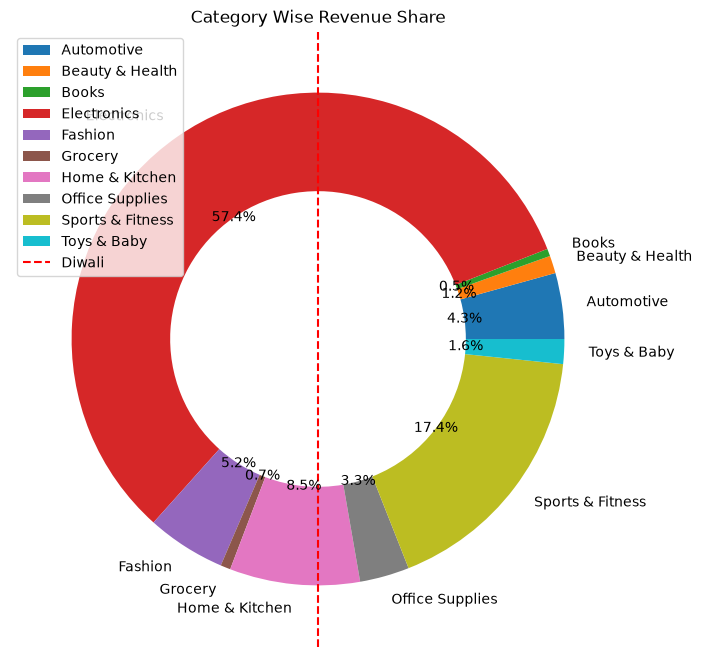

In [172]:
category_revenue = (
    order_items.groupby("category")["total_price"]
    .sum()
)

category_revenue.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(8,8),
    wedgeprops={"width":0.4}
)

plt.title("Category Wise Revenue Share")
plt.ylabel("")
plt.axvline(x="November", color="red", linestyle="--", label="Diwali")
plt.legend()
plt.savefig("category_wise_revenue.png", dpi=300, bbox_inches="tight")
plt.show()

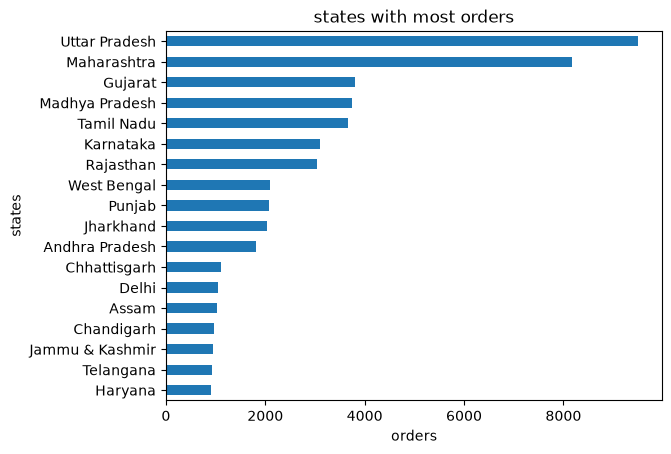

In [171]:
orders=pd.read_csv("datasets/orders.csv")
top_states = orders.groupby("state")["final_amount"].count().sort_values().plot(
    kind="barh",
    xlabel="orders",
    ylabel="states",
    title="states with most orders"
    )
plt.savefig("states_with_most_orders.png", dpi=300, bbox_inches="tight")


In [ ]:
order_status_dist = orders["status"].value_counts()
order_status_dist.sort_values(ascending=False).plot(kind="pie",wedgeprops={"width": 0.4},autopct="%1.f%%",title="Order Status Distribution")
orders

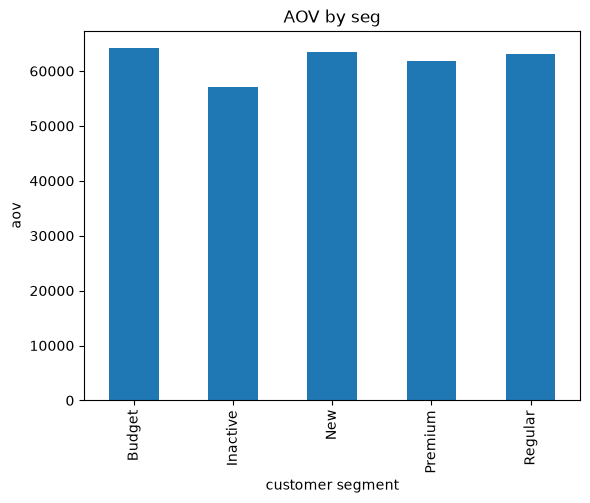

In [170]:

merged_df = pd.merge(customers,orders, on="customer_id")
segment_rev = merged_df.groupby("segment")["final_amount"].sum()

segment_orders = merged_df.groupby("segment")["order_id"].count()
aov = segment_rev/segment_orders

aov.plot(kind="bar",title="AOV by seg",xlabel="customer segment",ylabel="aov")
plt.savefig("AOV.png", dpi=300, bbox_inches="tight")
plt.show()
#avg_order_val_by_seg = merged_df["segment"](total_rev/total_orders)

#avg_order_val_by_seg

In [ ]:
orders